# Week 02 · Day 01
# Regression Foundations & Linear Regression

**Program:** Data Science & AI — 200-hour professional program  
**Business case:** AdventureWorks  
**Estimated classroom time:** 5 hours  
**Level:** Beginner to early intermediate  
**Language:** B2 English

---

## Instructor and learner guide

This notebook is designed as a teaching resource and a practical lab. Each section introduces one idea, demonstrates it with AdventureWorks order data, and then gives learners a task to complete.

- **Concept** explains the idea and why it matters.
- **Demonstration** shows a complete, runnable example.
- **Your turn** gives students a focused exercise.
- **Instructor note / solution** is separated from student tasks.

> **Important:** The data in this notebook is synthetic. It is generated with a fixed random seed so that every learner can reproduce the same dataset and results. It is designed for learning, not for real business decisions.

## Learning outcomes

By the end of this day, learners should be able to:

1. Explain what a regression problem is and identify a continuous prediction target.
2. Separate a dataset into features (`X`) and target (`y`).
3. Create a training set and a test set and explain why both are needed.
4. Build a baseline regression model and a Linear Regression model with scikit-learn.
5. Explain the meaning of coefficients and the intercept in a simple linear model.
6. Evaluate predictions using MAE, RMSE, and R², and explain the limitations of each metric.
7. Use residual analysis to identify patterns that a metric alone may hide.
8. Build a preprocessing-and-modeling pipeline that handles numeric and categorical features safely.
9. Avoid common mistakes such as target leakage and evaluating on training data.
10. Communicate model results in clear business language.

### Suggested 5-hour delivery plan

| Block | Focus | Suggested time |
|---|---|---:|
| 1 | Regression problem framing and dataset inspection | 35 min |
| 2 | Features, target, and train/test split | 35 min |
| 3 | Baseline and first Linear Regression model | 55 min |
| 4 | Coefficients, predictions, and regression metrics | 60 min |
| 5 | Residual analysis and pipeline workflow | 65 min |
| 6 | Mini project, review, and knowledge check | 50 min |

## Table of contents

1. The business problem: predict order revenue
2. Prepare and inspect the AdventureWorks dataset
3. Define features and target
4. Split data into training and test sets
5. Establish a baseline
6. Train your first Linear Regression model
7. Understand coefficients and the intercept
8. Evaluate regression models
9. Inspect residuals and prediction errors
10. Build a robust preprocessing pipeline
11. Common mistakes and professional workflow
12. Mini project: estimate revenue for new orders
13. Knowledge check and readiness checklist
14. Instructor solutions

# 1. The business problem: predict order revenue

AdventureWorks wants to estimate the **net revenue of an order** soon after the order details are entered. A reliable estimate can support sales planning, operational forecasting, and order review.

This is a **regression problem** because the output is a numeric quantity that can take many possible values (for example, 84.50, 129.99, or 642.20).

### Regression vs. classification

- **Regression** predicts a continuous numeric value, such as order revenue, delivery time, or product demand.
- **Classification** predicts a category, such as whether an order will be returned or whether a customer will churn.

The business question determines the type of machine learning problem. Do not choose an algorithm before defining what decision the model should support.

### Our prediction point

Assume the model is used after the order lines and shipping option are known, but before the final order revenue is confirmed. We may use:

- item quantity
- average unit price
- discount percentage
- shipping fee
- customer segment
- sales channel
- product category

We must not use information that is only known after the outcome, such as a final settlement amount or a post-delivery adjustment.

### A simple view of supervised learning

In supervised learning, the training data contains examples with known answers. The model learns a relationship between input features and a target.

For this notebook:

- **Features (`X`)** are the order details available to the model.
- **Target (`y`)** is the observed net order revenue.
- **Training** means fitting the model using historical examples.
- **Prediction** means estimating the target for new examples.

# 2. Prepare and inspect the AdventureWorks dataset

We will generate a compact but realistic synthetic dataset. It contains numeric and categorical fields, plus a small amount of missing data so that we can practise a professional preprocessing workflow later.

The target is generated from a business-like formula with random noise. Learners should understand that synthetic data has a known construction process; real business data is usually more complex.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

n_orders = 1200

customer_segments = ["Consumer", "Corporate", "Small Business"]
sales_channels = ["Website", "Mobile App", "Partner"]
product_categories = ["Electronics", "Home", "Accessories"]

orders = pd.DataFrame({
    "order_id": [f"AW-{50000 + i}" for i in range(n_orders)],
    "quantity": rng.integers(1, 9, size=n_orders),
    "unit_price": np.round(rng.uniform(12, 450, size=n_orders), 2),
    "discount_pct": np.round(rng.choice([0, 0.05, 0.10, 0.15, 0.20], size=n_orders,
                                       p=[0.35, 0.20, 0.25, 0.15, 0.05]), 2),
    "shipping_fee": np.round(rng.choice([0, 4.99, 7.99, 12.99, 18.99], size=n_orders), 2),
    "customer_segment": rng.choice(customer_segments, size=n_orders,
                                   p=[0.58, 0.27, 0.15]),
    "sales_channel": rng.choice(sales_channels, size=n_orders,
                                p=[0.48, 0.37, 0.15]),
    "product_category": rng.choice(product_categories, size=n_orders,
                                   p=[0.42, 0.33, 0.25])
})

segment_effect = orders["customer_segment"].map({
    "Consumer": 0.0, "Corporate": 5.0, "Small Business": 2.5
})
channel_effect = orders["sales_channel"].map({
    "Website": 0.0, "Mobile App": 1.5, "Partner": 3.0
})
category_effect = orders["product_category"].map({
    "Electronics": 2.0, "Home": 0.0, "Accessories": -1.0
})

order_subtotal = orders["quantity"] * orders["unit_price"] * (1 - orders["discount_pct"])

noise = rng.normal(loc=0, scale=12, size=n_orders)
orders["net_revenue"] = np.round(
    order_subtotal + orders["shipping_fee"] + segment_effect + channel_effect
    + category_effect + noise,
    2
)

# Add a small number of missing feature values for preprocessing practice.
for column in ["unit_price", "customer_segment"]:
    missing_rows = rng.choice(orders.index, size=18, replace=False)
    orders.loc[missing_rows, column] = np.nan

display(orders.head())
print(f"Rows: {orders.shape[0]:,} | Columns: {orders.shape[1]}")

,order_id,quantity,unit_price,discount_pct,shipping_fee,customer_segment,sales_channel,product_category,net_revenue
0,AW-50000,1,221.15,0.1,12.99,Consumer,Website,Home,221.23
1,AW-50001,7,345.51,0.1,18.99,Consumer,Website,Electronics,2198.21
2,AW-50002,6,407.66,0.0,12.99,Consumer,Website,Home,2476.85
3,AW-50003,4,327.66,0.1,7.99,Consumer,Website,Electronics,1205.06
4,AW-50004,4,433.89,0.1,7.99,Small Business,Mobile App,Electronics,1578.36


Rows: 1,200 | Columns: 9


### 2.1 Inspect the data before modeling

A professional workflow starts with inspection. Check:

- the number of rows and columns
- column names and data types
- missing values
- summary statistics
- whether the target is numeric and has a sensible range

Do not assume that a dataset is ready for modeling just because it loaded successfully.

In [2]:
print("Dataset information:")
orders.info()

print("\\nMissing values by column:")
display(orders.isna().sum().rename("missing_count").to_frame())

print("\\nNumeric summary:")
display(orders.describe().T)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          1200 non-null   object 
 1   quantity          1200 non-null   int64  
 2   unit_price        1182 non-null   float64
 3   discount_pct      1200 non-null   float64
 4   shipping_fee      1200 non-null   float64
 5   customer_segment  1182 non-null   object 
 6   sales_channel     1200 non-null   object 
 7   product_category  1200 non-null   object 
 8   net_revenue       1200 non-null   float64
dtypes: float64(4), int64(1), object(4)
memory usage: 84.5+ KB
\nMissing values by column:


,missing_count
order_id,0
quantity,0
unit_price,18
discount_pct,0
shipping_fee,0
customer_segment,18
sales_channel,0
product_category,0
net_revenue,0


\nNumeric summary:


,count,mean,std,min,25%,50%,75%,max
quantity,1200.0,4.531667,2.282909,1.00,3.0000,5.00,7.0000,8.00
unit_price,1182.0,234.058765,128.191354,12.23,119.9375,229.47,350.8050,449.75
discount_pct,1200.0,0.066667,0.061782,0.00,0.0000,0.05,0.1000,0.20
shipping_fee,1200.0,8.614725,6.559153,0.00,4.9900,7.99,12.9900,18.99
net_revenue,1200.0,987.863617,774.667625,13.86,350.7375,754.10,1478.4225,3547.39


### Exercise 1 — First data review

Before moving on, answer these questions in a Markdown cell:

1. How many orders are in the dataset?
2. Which columns contain missing values?
3. Which columns are numeric and which are categorical?
4. Why should `order_id` normally not be used as a predictive feature?
5. Does `net_revenue` look like a continuous numeric target?

**Deliverable:** Write 3–5 sentences describing whether the data is ready for a first model and what still needs attention.

# 3. Define features and target

The target is the value we want to predict. Features are the information used to make that prediction.

In scikit-learn, the common naming convention is:

- `X`: feature matrix (usually a DataFrame with one or more columns)
- `y`: target vector (usually a Series)

We will exclude `order_id` because it is an identifier, not a meaningful business measurement. We also exclude `net_revenue` from `X` because it is the answer we are trying to predict.

In [3]:
feature_columns = [
    "quantity",
    "unit_price",
    "discount_pct",
    "shipping_fee",
    "customer_segment",
    "sales_channel",
    "product_category"
]

X = orders[feature_columns].copy()
y = orders["net_revenue"].copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
display(X.head())
display(y.head())

Feature matrix shape: (1200, 7)
Target shape: (1200,)


,quantity,unit_price,discount_pct,shipping_fee,customer_segment,sales_channel,product_category
0,1,221.15,0.1,12.99,Consumer,Website,Home
1,7,345.51,0.1,18.99,Consumer,Website,Electronics
2,6,407.66,0.0,12.99,Consumer,Website,Home
3,4,327.66,0.1,7.99,Consumer,Website,Electronics
4,4,433.89,0.1,7.99,Small Business,Mobile App,Electronics


0     221.23
1    2198.21
2    2476.85
3    1205.06
4    1578.36
Name: net_revenue, dtype: float64

### Why must the target stay out of the features?

If `net_revenue` is included in `X`, the model receives the answer while learning to predict the answer. This is a form of **target leakage**. The resulting evaluation can look excellent, but the model cannot make a valid prediction when the target is unknown.

A good question to ask for every feature is:

> Would this value genuinely be available at the exact moment the prediction is made?

### Exercise 2 — Feature selection

1. Add `order_id` to a temporary feature list and explain why it is not a useful general predictor.
2. Imagine AdventureWorks also has a column called `refund_amount`, recorded after an order is completed. Should it be used to predict revenue before completion? Explain.
3. Identify one additional feature that might improve the model if it were available at prediction time.

**Do not train a model yet.** Focus on the business meaning and timing of the information.

# 4. Split data into training and test sets

A model must be evaluated on examples it did not use during training.

- The **training set** is used to learn model parameters.
- The **test set** is held back to estimate performance on unseen examples.

A common starting point is an 80/20 split. The exact ratio depends on the size and structure of the data.

`random_state` makes the split reproducible. For data with a time dimension, a random split may be inappropriate; a chronological split is often more realistic. We will use a random split for this introductory, independently generated order dataset.

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Training proportion:", round(len(X_train) / len(X), 2))
print("Test proportion:", round(len(X_test) / len(X), 2))

Training rows: 960
Test rows: 240
Training proportion: 0.8
Test proportion: 0.2


### Important: split before learning preprocessing rules

Any preprocessing step that learns information from data (for example, calculating a median for missing-value replacement) must be fitted using training data only. The learned transformation is then applied to the test data.

This prevents information from the test set from influencing the training process. Scikit-learn pipelines help enforce this discipline. See the official guidance on [common pitfalls and data leakage](https://scikit-learn.org/stable/common_pitfalls.html).

### Exercise 3 — Split reasoning

1. What would happen if we trained and evaluated on the same rows?
2. Why do we keep `y_test` separate from the model-fitting step?
3. If orders were recorded over 18 months and the goal was to predict next month, what kind of split would be more appropriate?

**Expected response:** Explain the idea, not only the code.

# 5. Establish a baseline

Before building a complex model, create a simple reference point. A baseline tells us how well we can perform without learning relationships between the features and the target.

For regression, a simple baseline predicts the **mean target value from the training set** for every test row. A useful model should improve on this baseline on data it has not seen.

In [5]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error

baseline_model = DummyRegressor(strategy="mean")
baseline_model.fit(X_train[["quantity"]], y_train)

baseline_predictions = baseline_model.predict(X_test[["quantity"]])
baseline_mae = mean_absolute_error(y_test, baseline_predictions)

print(f"Baseline MAE: ${baseline_mae:,.2f}")

Baseline MAE: $663.37


### Exercise 4 — Baseline interpretation

1. In plain English, what does the baseline predict for every order?
2. Why is it useful even though it ignores the features?
3. What would it mean if a new model had a higher MAE than this baseline?

Record your answer before continuing.

# 6. Train your first Linear Regression model

Linear Regression is a supervised learning algorithm used to predict a numeric target. It estimates a relationship between one or more input features and the target.

For a single feature, the model can be written as:

\[
\hat{y} = b_0 + b_1x
\]

For multiple features:

\[
\hat{y} = b_0 + b_1x_1 + b_2x_2 + \cdots + b_px_p
\]

Where:

- \(\hat{y}\) is the predicted value.
- \(b_0\) is the intercept.
- \(b_j\) is the coefficient for feature \(j\).
- \(x_j\) is the value of feature \(j\).

Ordinary Least Squares estimates coefficients by minimizing the sum of squared differences between observed and predicted target values. The model does not simply draw a line through every point; it finds the line or hyperplane that minimizes the total squared residual error.

### 6.1 Start with one feature

A single-feature model is easier to visualize. We will use `quantity` to predict order revenue. This is a teaching example, not necessarily the best business model, because order revenue also depends on price, discounts, and other details.

In [6]:
from sklearn.linear_model import LinearRegression

X_train_quantity = X_train[["quantity"]]
X_test_quantity = X_test[["quantity"]]

simple_model = LinearRegression()
simple_model.fit(X_train_quantity, y_train)

print("Intercept:", round(simple_model.intercept_, 2))
print("Quantity coefficient:", round(simple_model.coef_[0], 2))

Intercept: 46.51
Quantity coefficient: 208.2


### 6.2 Visualize the relationship

The scatter plot shows observed training orders. The line shows the model's fitted predictions for different quantities.

A fitted line summarizes an average linear relationship. It does not mean every order with the same quantity will have the same revenue.

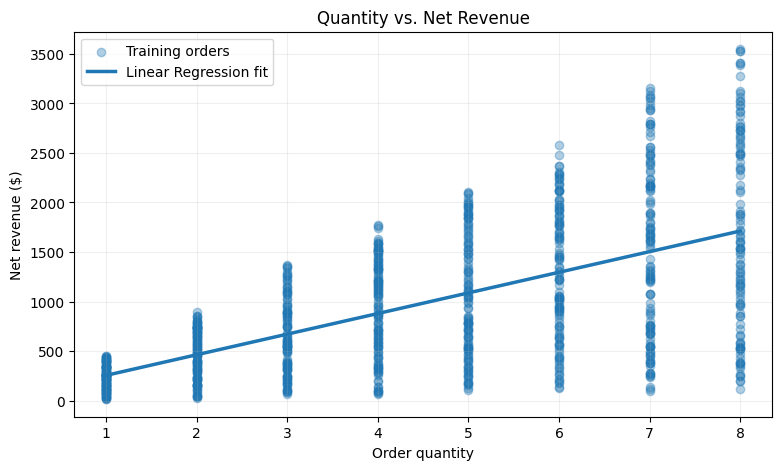

In [7]:
plt.figure(figsize=(9, 5))
plt.scatter(X_train_quantity["quantity"], y_train, alpha=0.35, label="Training orders")

quantity_range = pd.DataFrame({
    "quantity": np.arange(1, 9)
})
predicted_line = simple_model.predict(quantity_range)

plt.plot(quantity_range["quantity"], predicted_line, linewidth=2.5,
         label="Linear Regression fit")
plt.xlabel("Order quantity")
plt.ylabel("Net revenue ($)")
plt.title("Quantity vs. Net Revenue")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

### 6.3 Predict using the simple model

After fitting, use `predict()` to estimate values for new feature rows. The model expects the same feature structure it saw during training.

In [8]:
sample_orders = X_test_quantity.head(5)
sample_predictions = simple_model.predict(sample_orders)

prediction_preview = sample_orders.copy()
prediction_preview["predicted_revenue"] = np.round(sample_predictions, 2)
display(prediction_preview)

,quantity,predicted_revenue
1178,3,671.10
865,6,1295.69
101,2,462.90
439,4,879.30
58,6,1295.69


### Exercise 5 — One-feature model

1. Train a model using `unit_price` only. Remember to handle missing values first, or use a subset without missing values for this focused exercise.
2. Plot `unit_price` against `net_revenue`.
3. Compare the relationship with the quantity model.
4. Explain why one feature is unlikely to capture all variation in order revenue.

**Hint:** For this exercise only, use `X_train["unit_price"].notna()` to select rows with a known unit price.

# 7. Understand coefficients and the intercept

A coefficient describes the model's estimated change in prediction when a feature increases by one unit, while other features are held constant.

For example, in a model using quantity, a coefficient of 35 would mean that one additional unit is associated with an estimated $35 increase in predicted revenue, assuming the other included features remain unchanged.

The intercept is the model's predicted target when all feature values are zero. It may be mathematically required even when a zero-valued order is not a realistic business case.

**Important:** A coefficient describes an association learned by the model. It does not prove that changing the feature will cause the target to change.

### 7.1 Fit a multiple-feature model using numeric inputs

First, use only numeric columns and remove rows with missing numeric feature values for this focused demonstration. Later, we will build a pipeline that handles missing values and categorical columns properly.

In [9]:
numeric_features = ["quantity", "unit_price", "discount_pct", "shipping_fee"]

numeric_train = X_train[numeric_features].copy()
numeric_test = X_test[numeric_features].copy()

train_complete = numeric_train.notna().all(axis=1)
test_complete = numeric_test.notna().all(axis=1)

numeric_model = LinearRegression()
numeric_model.fit(numeric_train.loc[train_complete], y_train.loc[train_complete])

numeric_predictions = numeric_model.predict(numeric_test.loc[test_complete])

coefficient_table = pd.DataFrame({
    "feature": numeric_features,
    "coefficient": numeric_model.coef_
}).sort_values("coefficient", key=lambda s: s.abs(), ascending=False)

print(f"Intercept: ${numeric_model.intercept_:,.2f}")
display(coefficient_table)

Intercept: $-932.61


,feature,coefficient
2,discount_pct,-954.594256
0,quantity,218.645300
1,unit_price,4.238429
3,shipping_fee,0.338103


### Interpreting coefficients responsibly

- Coefficients have units. A coefficient for `quantity` is measured in dollars per additional unit.
- Coefficients depend on which other features are included.
- Strongly related features can make individual coefficients unstable or difficult to interpret.
- A coefficient's sign does not prove a causal relationship.
- The intercept may not have a direct business interpretation.

Do not compare the raw size of coefficients across features with very different units without considering scale.

### Exercise 6 — Coefficient interpretation

Use the coefficient table:

1. Which numeric feature has the largest absolute coefficient?
2. What does the sign of the `discount_pct` coefficient suggest in this fitted model?
3. Why should you avoid saying that a coefficient proves causation?
4. Why might the coefficient for `unit_price` be large compared with the coefficient for `discount_pct`?

Write your interpretation as if you were explaining it to an AdventureWorks sales manager.

# 8. Evaluate regression models

A model's performance must be measured on data that was not used to fit it. We will use three common regression metrics.

### Mean Absolute Error (MAE)

MAE is the average absolute difference between actual and predicted values. If MAE is $18, predictions are off by $18 on average in absolute terms.

### Root Mean Squared Error (RMSE)

RMSE is the square root of the average squared error. It uses the same unit as the target (dollars here) and penalizes large errors more strongly than MAE.

### R-squared (R²)

R² compares the model with a simple mean-prediction reference. A value of 1 is a perfect fit; 0 means the model performs like predicting the test-set mean in the R² definition; a negative value means it performs worse than that reference.

R² is not the percentage of predictions that are correct. It is also not proof that a model is useful for the business.

In [10]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Evaluate the simple one-feature model on its matching test rows.
simple_predictions = simple_model.predict(X_test_quantity)

simple_mae = mean_absolute_error(y_test, simple_predictions)
simple_rmse = np.sqrt(mean_squared_error(y_test, simple_predictions))
simple_r2 = r2_score(y_test, simple_predictions)

print(f"MAE : ${simple_mae:,.2f}")
print(f"RMSE: ${simple_rmse:,.2f}")
print(f"R²  : {simple_r2:.3f}")

MAE : $486.97
RMSE: $605.79
R²  : 0.409


### 8.1 Compare with the baseline

A model should be compared with a baseline using the same test observations and metric. The numeric-only demonstration above excludes rows with missing numeric values, so compare it only with a baseline calculated on that same subset if you evaluate it.

For the simple quantity model, the baseline and model both use the full test set because quantity has no missing values.

In [11]:
comparison = pd.DataFrame({
    "model": ["Mean baseline", "Linear Regression (quantity)"],
    "MAE": [
        mean_absolute_error(y_test, baseline_predictions),
        simple_mae
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, baseline_predictions)),
        simple_rmse
    ],
    "R2": [
        r2_score(y_test, baseline_predictions),
        simple_r2
    ]
})

display(comparison.round(3))

,model,MAE,RMSE,R2
0,Mean baseline,663.375,788.050,-0.001
1,Linear Regression (quantity),486.972,605.786,0.409


### Choosing a metric is a business decision

Imagine an order forecast is used to plan staffing and packaging capacity.

- MAE is easy to explain as a typical absolute error.
- RMSE gives extra weight to occasional large misses.
- R² describes how much variation is explained relative to a mean baseline, but it does not express the error in dollars.

A business team may care more about avoiding large underestimates than large overestimates. In that case, additional analysis or a different loss function may be needed.

### Exercise 7 — Metric selection

1. If a manager asks, “How many dollars wrong are our predictions on average?”, which metric would you report first?
2. Why might RMSE be much larger than MAE?
3. Can R² be negative? What would that tell you?
4. Why is it not enough to report R² alone?

Answer using the AdventureWorks order-revenue context.

# 9. Inspect residuals and prediction errors

A **residual** is the difference between an actual value and its predicted value:

\[
e_i = y_i - \hat{y}_i
\]

- A positive residual means the model underpredicted.
- A negative residual means the model overpredicted.
- A residual near zero means the prediction was close.

Residual analysis can reveal patterns that a single metric cannot show. Ideally, residuals should not show a clear systematic pattern. Curved patterns, changing spread, or clusters can indicate that the model is missing important structure.

,actual,predicted,residual
1178,425.23,671.100147,-245.870147
865,1570.12,1295.692744,274.427256
101,326.81,462.902615,-136.092615
439,279.06,879.297679,-600.237679
58,1650.32,1295.692744,354.627256
1120,39.92,254.705082,-214.785082
323,2036.91,1712.087808,324.822192
974,101.41,462.902615,-361.492615
411,517.10,462.902615,54.197385
855,318.67,1503.890276,-1185.220276


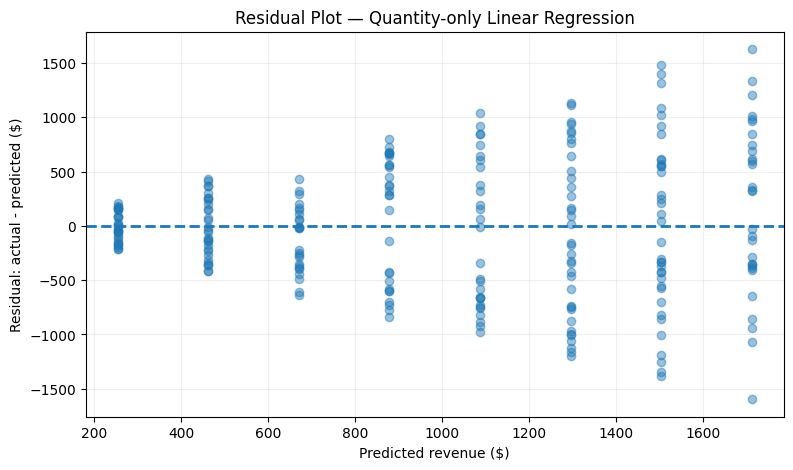

In [12]:
residuals = y_test - simple_predictions

residual_frame = pd.DataFrame({
    "actual": y_test,
    "predicted": simple_predictions,
    "residual": residuals
})

display(residual_frame.head(10))

plt.figure(figsize=(9, 5))
plt.scatter(simple_predictions, residuals, alpha=0.45)
plt.axhline(0, linestyle="--", linewidth=2)
plt.xlabel("Predicted revenue ($)")
plt.ylabel("Residual: actual - predicted ($)")
plt.title("Residual Plot — Quantity-only Linear Regression")
plt.grid(alpha=0.2)
plt.show()

### Exercise 8 — Read the residual plot

1. What does a point above the horizontal zero line mean?
2. What does a point below the line mean?
3. Do you see a pattern in the spread of errors?
4. What additional feature could help explain some of the errors?

Do not claim that the model is good or bad from the plot alone. Combine the visual evidence with metrics and business requirements.

# 10. Build a robust preprocessing pipeline

The earlier numeric-only example was useful for understanding the model, but a real dataset often contains missing values and categorical columns.

A professional scikit-learn workflow can combine preprocessing and modeling in a single `Pipeline`:

- Numeric features: fill missing values using the training median.
- Categorical features: fill missing values using the most frequent category.
- Categorical encoding: convert categories into numeric indicator columns using One-Hot Encoding.
- Model: fit Linear Regression on the transformed data.

`ColumnTransformer` applies different preprocessing steps to different columns. `Pipeline` chains preprocessing and the estimator so that the same learned transformations are applied consistently at training and prediction time.

In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

numeric_features = ["quantity", "unit_price", "discount_pct", "shipping_fee"]
categorical_features = ["customer_segment", "sales_channel", "product_category"]

numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_preprocessor, numeric_features),
    ("categorical", categorical_preprocessor, categorical_features)
])

linear_regression_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_regression_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different tra

### Why scale numeric features?

Standardization transforms a numeric feature so that it is centered around zero and has a standard deviation close to one, based on the training data. Scaling is not required for ordinary least squares to produce a mathematical solution, but it can make coefficients easier to compare in standardized units and is useful when later learning algorithms are sensitive to feature scale.

The categorical variables are one-hot encoded because Linear Regression requires numeric inputs. We use `handle_unknown="ignore"` so that a category not seen during training does not cause prediction to fail.

### 10.1 Fit the complete pipeline

Notice that we pass the original training DataFrame to the pipeline. It learns imputation values, scaling parameters, and category levels from the training data only.

In [14]:
linear_regression_pipeline.fit(X_train, y_train)

pipeline_predictions = linear_regression_pipeline.predict(X_test)

pipeline_metrics = {
    "MAE": mean_absolute_error(y_test, pipeline_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_test, pipeline_predictions)),
    "R2": r2_score(y_test, pipeline_predictions)
}

for metric, value in pipeline_metrics.items():
    if metric in ["MAE", "RMSE"]:
        print(f"{metric}: ${value:,.2f}")
    else:
        print(f"{metric}: {value:.3f}")

MAE: $214.36
RMSE: $288.25
R2: 0.866


### 10.2 Compare the baseline, simple model, and full pipeline

The pipeline uses more information than the quantity-only model. A better score is not guaranteed; the test set tells us how well the model generalizes.

In [15]:
all_model_comparison = pd.DataFrame([
    {
        "model": "Mean baseline",
        "MAE": mean_absolute_error(y_test, baseline_predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, baseline_predictions)),
        "R2": r2_score(y_test, baseline_predictions)
    },
    {
        "model": "Linear Regression (quantity)",
        "MAE": simple_mae,
        "RMSE": simple_rmse,
        "R2": simple_r2
    },
    {
        "model": "Linear Regression (full pipeline)",
        "MAE": pipeline_metrics["MAE"],
        "RMSE": pipeline_metrics["RMSE"],
        "R2": pipeline_metrics["R2"]
    }
])

display(all_model_comparison.round(3))

,model,MAE,RMSE,R2
0,Mean baseline,663.375,788.050,-0.001
1,Linear Regression (quantity),486.972,605.786,0.409
2,Linear Regression (full pipeline),214.363,288.249,0.866


### 10.3 Predict a new order

A trained pipeline can accept a DataFrame with the same feature columns used during training. This is important: new data must follow the same schema and meaning as training data.

In [16]:
new_order = pd.DataFrame([{
    "quantity": 3,
    "unit_price": 89.99,
    "discount_pct": 0.10,
    "shipping_fee": 7.99,
    "customer_segment": "Consumer",
    "sales_channel": "Website",
    "product_category": "Electronics"
}])

estimated_revenue = linear_regression_pipeline.predict(new_order)[0]

print(f"Estimated net revenue: ${estimated_revenue:,.2f}")

Estimated net revenue: $19.66

### Exercise 9 — Pipeline practice

1. Add a new order with a `sales_channel` value not seen in the training data, such as `"Store Kiosk"`.
2. Use the pipeline to predict its revenue.
3. Explain why `handle_unknown="ignore"` is useful.
4. Change the quantity from 2 to 5 while keeping the other values fixed. Compare the predictions.
5. Explain why this is a model-based estimate, not a guaranteed final invoice value.

# 11. Common mistakes and professional workflow

| Mistake | Why it is a problem | Better practice |
|---|---|---|
| Evaluating on training data | Performance may look too optimistic | Keep a separate test set |
| Including the target in `X` | The model is given the answer | Define the prediction target and prediction time clearly |
| Preprocessing before splitting | Test information can leak into training | Split first; fit preprocessing on training data |
| Fitting transformations separately | Training and prediction data may be transformed differently | Use a Pipeline |
| Using only R² | It does not explain error in business units | Report MAE/RMSE and R² with context |
| Treating coefficients as causal effects | Association is not causation | Use careful, non-causal language |
| Ignoring residuals | Systematic errors can remain hidden | Inspect residuals and investigate patterns |
| Assuming a random split is always valid | Time-related data can leak future patterns | Use a time-aware split when predicting the future |

### A reusable modeling checklist

1. Define the business question and prediction time.
2. Identify the target and eligible features.
3. Inspect data types, missing values, and suspicious columns.
4. Split the data appropriately.
5. Establish a baseline.
6. Build a preprocessing-and-modeling pipeline.
7. Evaluate on held-out data.
8. Inspect residuals and error cases.
9. Compare results with business requirements.
10. Document assumptions and limitations.

### Exercise 10 — Spot the problem

For each situation, identify the issue and propose a correction.

**A.** A developer calculates the median of `unit_price` using the full dataset before splitting into train and test sets.

**B.** A model is evaluated using the same rows used by `fit()`.

**C.** The model has an R² of 0.92, so the analyst tells the business that 92% of orders will be predicted correctly.

**D.** The model uses `refund_amount`, which is only known after the order is completed.

**E.** A model is trained with one-hot encoding, but a separate manual encoding process is used for incoming production data.

# 12. Mini project — AdventureWorks Order Revenue Estimator

## Business brief

The AdventureWorks sales operations team wants a first model that estimates net order revenue from order details. Your task is to build, evaluate, and explain a Linear Regression solution.

### Required tasks

**Part A — Frame the problem**
1. State why this is a regression problem.
2. Define the target and list the eligible features.
3. Explain why `order_id` is excluded.

**Part B — Build the workflow**
4. Create a reproducible train/test split.
5. Establish a mean baseline.
6. Build a preprocessing pipeline for numeric and categorical columns.
7. Fit a Linear Regression model.

**Part C — Evaluate**
8. Calculate MAE, RMSE, and R² on the test set.
9. Compare the model against the baseline.
10. Plot predicted vs. actual revenue.
11. Plot residuals and describe any visible pattern.

**Part D — Apply**
12. Predict revenue for at least three new orders.
13. Explain which business inputs have the strongest practical influence on the estimate, without claiming causation.

**Part E — Communicate**
14. Write a short business summary (100–150 words) containing the test metrics, one limitation, and a recommendation.

### Acceptance criteria

- The notebook runs from top to bottom without manual file downloads.
- The target is not included in the features.
- The test set is not used during fitting or preprocessing.
- The model is compared with a baseline.
- The report includes at least two error metrics and R².
- The interpretation is accurate and avoids causal claims.

## Mini project — Student workspace

Complete the following cells. Do not open the instructor solution until you have attempted the project.

In [17]:
# 1. Define the project feature columns and target.
project_features = [
    "quantity", "unit_price", "discount_pct", "shipping_fee",
    "customer_segment", "sales_channel", "product_category"
]

X_project = orders[project_features].copy()
y_project = orders["net_revenue"].copy()

# 2. Create a train/test split.
X_project_train, X_project_test, y_project_train, y_project_test = train_test_split(
    X_project, y_project, test_size=0.20, random_state=RANDOM_STATE
)

# TODO: Build a preprocessing pipeline and LinearRegression model.
# TODO: Fit only on the training data.
# TODO: Predict the test data and calculate MAE, RMSE, and R2.

In [18]:
# 3. Create at least three new orders and predict their revenue.
new_orders_project = pd.DataFrame([
    {
        "quantity": 2, "unit_price": 49.99, "discount_pct": 0.05,
        "shipping_fee": 4.99, "customer_segment": "Consumer",
        "sales_channel": "Website", "product_category": "Accessories"
    },
    {
        "quantity": 1, "unit_price": 329.00, "discount_pct": 0.10,
        "shipping_fee": 12.99, "customer_segment": "Corporate",
        "sales_channel": "Partner", "product_category": "Electronics"
    },
    {
        "quantity": 4, "unit_price": 34.50, "discount_pct": 0.00,
        "shipping_fee": 7.99, "customer_segment": "Small Business",
        "sales_channel": "Mobile App", "product_category": "Home"
    }
])

# TODO: Replace `project_model` with the name of your fitted pipeline.
# project_estimates = project_model.predict(new_orders_project)
# display(new_orders_project.assign(estimated_revenue=project_estimates))

# 13. Knowledge check

Answer without looking back at the explanations.

1. What makes a problem a regression problem?
2. What is the difference between `X` and `y`?
3. Why do we keep a test set?
4. What does `fit()` do?
5. What does `predict()` do?
6. What does a positive residual mean?
7. Which metric reports average absolute error in the target's units?
8. Why does RMSE penalize large errors more than MAE?
9. Can R² be negative?
10. Why should preprocessing be fitted only on training data?
11. What is the purpose of `ColumnTransformer`?
12. Why is a pipeline useful when moving from a notebook to a repeatable workflow?

# 14. Summary and readiness checklist

## Key takeaways

- Regression predicts a numeric target.
- Features must be available at the prediction point.
- A train/test split helps estimate generalization to unseen examples.
- A baseline provides a minimum reference for model performance.
- Linear Regression estimates coefficients that minimize squared residual error.
- MAE, RMSE, and R² answer different evaluation questions.
- Residual analysis helps reveal systematic prediction errors.
- Pipelines keep preprocessing and modeling consistent and reduce leakage risk.
- A model's technical score must be interpreted in its business context.

## Ready for Day 02?

You are ready to move on when you can:

- [ ] Explain regression and identify a continuous target.
- [ ] Separate features from the target without leakage.
- [ ] Explain why and how data is split.
- [ ] Train a Linear Regression model with scikit-learn.
- [ ] Interpret coefficients carefully.
- [ ] Calculate and explain MAE, RMSE, and R².
- [ ] Read a residual plot.
- [ ] Build a preprocessing pipeline with imputation and one-hot encoding.
- [ ] Compare a model with a baseline.
- [ ] Communicate model limitations in business language.

## Preview of Day 02

The next session will move from a first regression model to **model generalization and reliable evaluation**: validation strategy, cross-validation, underfitting and overfitting, and how to compare models without repeatedly tuning against the test set.

# Instructor solutions — selected exercises

> Instructor-only section. Hide or remove this section before distributing a student copy if you want learners to complete all exercises independently.

### Exercise 1 — Expected observations
- There are 1,200 rows.
- `unit_price` and `customer_segment` contain missing values.
- Numeric columns include quantity, unit price, discount, shipping fee, and net revenue; customer segment, sales channel, and product category are categorical.
- `order_id` is an identifier and does not represent a stable business relationship.
- `net_revenue` is a continuous numeric target.

### Exercise 2 — Key points
- IDs can encode accidental ordering or row identity rather than reusable predictive information.
- `refund_amount` is not available at the defined prediction point and would create leakage.
- Useful additional features could include promotion type, customer tenure, or delivery region, if known before the prediction.

### Exercise 3 — Key points
- Training-set evaluation measures how well the model fits data it has already seen and can be overly optimistic.
- The test target is held back for final evaluation.
- For future prediction, use an earlier period for training and a later period for testing.

### Exercise 4 — Key points
- The baseline predicts the training target mean for every test order.
- It gives a reference point that a useful model should beat.
- A higher MAE means the model has larger average absolute errors than the baseline.

### Exercise 5 — Example solution

In [19]:
# Instructor example: one-feature unit-price model, using complete rows only.
unit_price_train_mask = X_train["unit_price"].notna()
unit_price_test_mask = X_test["unit_price"].notna()

unit_price_model = LinearRegression()
unit_price_model.fit(
    X_train.loc[unit_price_train_mask, ["unit_price"]],
    y_train.loc[unit_price_train_mask]
)

unit_price_predictions = unit_price_model.predict(
    X_test.loc[unit_price_test_mask, ["unit_price"]]
)

print("Unit-price-only MAE:",
      f"${mean_absolute_error(y_test.loc[unit_price_test_mask], unit_price_predictions):,.2f}")

Unit-price-only MAE: $441.46


### Exercise 6 — Interpretation guidance
The exact coefficients depend on the generated sample and split. Learners should describe the direction and units of each coefficient, and should state that coefficients are conditional associations, not causal effects.

### Exercise 7 — Metric guidance
- MAE is usually the most direct answer to “average absolute dollars wrong.”
- RMSE can be larger when a model makes a small number of large errors.
- R² can be negative when the model performs worse than the mean-prediction reference.
- R² alone does not express the typical error in dollars.

### Exercise 8 — Residual guidance
- Above zero: underprediction.
- Below zero: overprediction.
- Look for a systematic curve, changing spread, or clusters.
- Price, discount, category, and channel may explain variation not captured by quantity alone.

### Exercise 9 — Pipeline guidance
The pipeline accepts an unseen category because `OneHotEncoder(handle_unknown="ignore")` does not fail when it encounters a new category. The category is not assigned a learned effect; the corresponding encoded contribution is effectively absent. This is robust execution, not evidence that the model understands the new category.

### Exercise 10 — Corrections
- **A:** Data leakage through preprocessing. Split first and fit the imputer on training data only.
- **B:** Training performance is not an unbiased estimate of unseen performance. Evaluate on a held-out test set.
- **C:** R² is not classification accuracy. Explain it as variance explained relative to a mean baseline.
- **D:** Target leakage. Exclude information unavailable at prediction time.
- **E:** Inconsistent preprocessing. Keep transformations and model together in one pipeline.

### Mini project — Reference implementation

In [20]:
# Instructor reference implementation for the mini project.
project_numeric = ["quantity", "unit_price", "discount_pct", "shipping_fee"]
project_categorical = ["customer_segment", "sales_channel", "product_category"]

project_preprocessor = ColumnTransformer(transformers=[
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), project_numeric),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), project_categorical)
])

project_model = Pipeline([
    ("preprocessor", project_preprocessor),
    ("model", LinearRegression())
])

project_model.fit(X_project_train, y_project_train)
project_predictions = project_model.predict(X_project_test)

print(f"Project MAE : ${mean_absolute_error(y_project_test, project_predictions):,.2f}")
print(f"Project RMSE: ${np.sqrt(mean_squared_error(y_project_test, project_predictions)):,.2f}")
print(f"Project R2  : {r2_score(y_project_test, project_predictions):.3f}")

project_estimates = project_model.predict(new_orders_project)
display(new_orders_project.assign(
    estimated_revenue=np.round(project_estimates, 2)
))

Project MAE : $214.36
Project RMSE: $288.25
Project R2  : 0.866


,quantity,unit_price,discount_pct,shipping_fee,customer_segment,sales_channel,product_category,estimated_revenue
0,2,49.99,0.05,4.99,Consumer,Website,Accessories,-308.01
1,1,329.00,0.10,12.99,Corporate,Partner,Electronics,553.42
2,4,34.50,0.00,7.99,Small Business,Mobile App,Home,85.49


## Suggested instructor discussion prompts

1. The synthetic target contains a largely linear component. How might performance change on messy real sales data?
2. What would happen if the prediction had to be made before the shipping fee was known?
3. Should the business use one model for every product category, or compare segment-specific models later?
4. What additional evaluation would be required before deploying a revenue estimator?
5. What is the difference between a model that predicts well and a model that supports a useful business decision?

## Technical references

- [Scikit-learn — LinearRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html)
- [Scikit-learn — Model evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html)
- [Scikit-learn — Common pitfalls and data leakage](https://scikit-learn.org/stable/common_pitfalls.html)
- [Scikit-learn — Preprocessing data](https://scikit-learn.org/stable/modules/preprocessing.html)
- [Scikit-learn — Pipelines and composite estimators](https://scikit-learn.org/stable/modules/compose.html)

**End of Week 02 · Day 01**